# 🎓 Semester at the study office · starter notebook

**The situation.** About one first-year student in five leaves the university during the first semester. Many of
them could have been helped: a conversation with an adviser, a study group, help with money. But the study office
has only **three advisers**. At the end of **week 6** they can hold about **40 conversations**.

**Your job:** build a model that helps the office decide *who* to talk to, find out what **mistakes** it makes
(students worried for nothing, students missed), turn it into a **rule** the office can use, and then build a small
**Streamlit app** for the office.

**How to work.** Go through the steps in order. Each ✏️ cell is yours to write. Use the hotel notebook (session 10) as your template: it
does every step for hotel bookings. AI assistants are welcome for the code, but make sure you understand each step:
you will explain it in your video. `GUIDE.md` explains the terms on one page.

*The students are synthetic, but every profile is resampled from a real student (UCI "Predict students' dropout
and academic success", 4,424 students, CC BY 4.0), and the risk of leaving follows a model fitted on the real
outcomes.*

In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost as xgb

# the data lives on GitHub, so this works in Colab without uploading anything
URL = "https://raw.githubusercontent.com/aaubs/ds-master/main/assignments/study-office/data/"
BASE = "data/" if os.path.exists("data/history_week6.csv") else URL
history = pd.read_csv(BASE + "history_week6.csv")   # past students, with what happened
new = pd.read_csv(BASE + "new_week6.csv")           # this year's students, week 6: what happens is not known yet
print(history.shape, new.shape)
history.head()

(2686, 24) (703, 20)


,student_id,cohort,age,admission_grade,international,first_gen,su_scholarship,fees_owed,moved_from_home,married,...,logins_last3,logins_trend,submitted_share,missed_last3,quiz_mean,weeks_since_login,ects_passed_sem1,deregistration_form_opened,last_login_week,left
0,S230000,2023,19,9.1,0,1,0,0,1,0,...,23.0,-3.67,1.00,0.0,70.83,0.0,6,0,12,0
1,S230001,2023,35,5.2,0,0,0,0,0,0,...,16.0,1.00,0.83,0.0,55.20,0.0,5,0,12,0
2,S230002,2023,18,6.9,0,1,0,0,0,0,...,15.0,-1.67,1.00,0.0,67.33,0.0,8,0,12,0
3,S230003,2023,21,7.2,0,1,0,0,0,0,...,7.0,-1.67,0.33,2.0,70.00,0.0,5,0,12,0
4,S230004,2023,21,7.1,0,1,0,0,1,0,...,15.0,-1.33,0.67,0.0,66.75,0.0,3,0,12,0


---
## 0 · Think first 🤔

Before any code, write down in your own words:

1. **Who decides what?** Who uses the model's output, and what exactly do they decide?
2. **When?** What does the office know about a student at the end of week 6, and what does it not know yet?
3. **The two mistakes.** The model can flag a student who would have stayed anyway (a **false alarm**, a *false
   positive*), or miss a student who then leaves (a **missed student**, a *false negative*). What does each cost,
   and for whom?
4. **Which is worse?** Is one false alarm as bad as one missed student?



OUR INPUT

1. The model should give each student a risk score. The advisers at the study
   office decide ***who to invite for a helping conversation*** at the end of week 6. The model indicates probability and
   the university staff decide. 

2. At the end of week 6 the office knows data from enrolment (age, programme, admission grade,
   international or not), the money and life situation (SU grant, fees owed, moved from home) and
   six weeks of study activity (logins, assignments handed in, missed assignments, quiz scores). 
   They ***don't know*** yet the exam results and ECTS points and **if the student will leave**.


3. False Positive **(False alarm)** : we contact a student who would have stayed in the programme. It costs
     adviser time, which could have been used for another student, and it can worry the student.

     False Negative **(Missed Student)**:* a student at risk is not helped and leaves. The student loses the
     the knowledge, money and maybe motivation to study in the future; the university loses the student and the drop rate increases wich does not look good for the image.
     
4. One **missed student is much worse** than one false alarm: leaving university is a
   big and often life changing event, while an invitation to counceling ("we talk to many first-year students,
   how is it going?") costs little in comparison.  But false alarms **are not free**: with only 40 conversations, every false alarm
   takes a place from a student who really needed it

---
## 1 · Look at the data

**`history_week6.csv`**: one row per student from the 2023, 2024 and 2025 cohorts who was still enrolled at the end
of week 6, with what the office knew then, and **`left`** (1 = left later that semester). **`new_week6.csv`**: the
2026 students, this week. This is the list the office has to act on.

| Column | Meaning |
|---|---|
| `age`, `gender`, `programme`, `evening_programme` | from enrolment |
| `admission_grade` | grade point average from upper secondary school (Danish scale) |
| `international`, `first_gen` | international student; first in the family at university |
| `su_scholarship`, `fees_owed`, `moved_from_home`, `married` | money and life situation (0/1) |
| `logins_total`, `logins_last3`, `logins_trend` | logins on the learning platform: weeks 1–6, the last three weeks, and the change |
| `submitted_share`, `missed_last3` | share of weekly assignments handed in; assignments missed in the last three weeks |
| `quiz_mean`, `weeks_since_login` | average quiz score; weeks since the last login |
| `ects_passed_sem1`, `deregistration_form_opened`, `last_login_week` | ⚠️ see step 2 |
| `left` | **the target**: 1 = left later in the semester |

✏️ **Your turn.** How many students leave? Compare the share who left across a few columns you think matter, for example `programme`, `fees_owed`, `submitted_share`. (Template: section 1 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

`history['left'].mean()`; `history.groupby('fees_owed')['left'].mean()`; for a number, cut it into groups first: `history.groupby(pd.cut(history['submitted_share'], [0, .5, .8, 1], include_lowest=True))['left'].mean()`.
</details>

In [3]:
# 1 how many students leave?

print(f"{len(history)} students & {history['left'].sum()} left & share who left: {history['left'].mean():.1%}")

# 2 who left by category (size = number of total students, sum = the ones that left, mean = share who left)
for col in ["programme", "fees_owed", "su_scholarship", "international"]:
    print("\n", history.groupby(col)["left"].agg(["size","sum","mean"]).round(3)
          .sort_values("mean", ascending=False))

    # 3 · assignments handed in: cut into groups, then comparison
history.groupby(pd.cut(history["submitted_share"], [0, .5, .8, 1], include_lowest=True),
                observed=True)["left"].agg(["size", "sum", "mean"]).round(3)



    
    
    

2686 students & 219 left & share who left: 8.2%

                                size  sum   mean
programme                                      
Software                         96   21  0.219
Sustainable Biotechnology       187   30  0.160
Business Administration         342   42  0.123
Learning & Innovation            93    9  0.097
Communication & Digital Media   680   58  0.085
Tourism                         143   11  0.077
Social Work                     371   17  0.046
Health Science                  774   31  0.040

            size  sum   mean
fees_owed                  
1           312   59  0.189
0          2374  160  0.067

                 size  sum   mean
su_scholarship                  
0               1972  196  0.099
1                714   23  0.032

                size  sum   mean
international                  
0              2085  174  0.083
1               601   45  0.075


,size,sum,mean
submitted_share,,,
"(-0.001, 0.5]",409,87,0.213
"(0.5, 0.8]",491,48,0.098
"(0.8, 1.0]",1786,84,0.047


# Results:
- 8.2 % of the students still enrolled at week 6 leave later (219 of 2,686), so "leaving" is rare
- programme matters (Students who Leave) Software 22%  , Sustainable Biotech 16 % vs Health Science & Social Work 4 % 
- money matters: fees owed 19 % vs 7 %; SU grant 3 % vs 10 %         **# 0 = NO  1 = YES**
- international vs domestic: about the same (7.5 % vs 8.3 %)

Results: handing in ≤ 50 % of the assignments -> 21 % leave; 50-80% 10% leave > 80 % -> 5 % leave (4x lower)


---
## 2 · What is known when? (leakage)

The model will be used **at the end of week 6**. A column that is only filled in later makes the model look
brilliant here and useless in October. Compare the two files: which columns does the history have that this week's
list does not?

In [4]:
sorted(set(history.columns) - set(new.columns))

['deregistration_form_opened', 'ects_passed_sem1', 'last_login_week', 'left']

✏️ **Your turn.** For each of these columns: when is it recorded? Would the office know it at the end of week 6? Write one sentence each, then make a list `features` of the columns the model may use (not `student_id`, `cohort`, the leaks, or the target). (Template: the leakage hunt, section 3 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

ECTS points are awarded after the exams. A deregistration form is opened by students who are about to leave. The *last* login week is computed over the whole semester. `left` is the target itself.
</details>

In [5]:
# how strongly do the leaks give the answer away? (Bonus, LEAKEAGE HUNT)
print(history.groupby("deregistration_form_opened")["left"].mean().round(3).to_dict())
print(history.groupby("left")[["ects_passed_sem1", "last_login_week"]].mean().round(2))

# columns the model may NOT use
leaks = ["ects_passed_sem1", "deregistration_form_opened", "last_login_week"]
drop = ["student_id", "cohort", "left"] + leaks

# columns the model may use: everything the office knows at the end of week 6
features = [c for c in history.columns if c not in drop]
print(len(features), "features:", features)

{0: 0.016, 1: 0.909}
      ects_passed_sem1  last_login_week
left                                   
0                 5.57            11.97
1                 1.73             8.56
18 features: ['age', 'admission_grade', 'international', 'first_gen', 'su_scholarship', 'fees_owed', 'moved_from_home', 'married', 'evening_programme', 'programme', 'gender', 'logins_total', 'logins_last3', 'logins_trend', 'submitted_share', 'missed_last3', 'quiz_mean', 'weeks_since_login']


# Results: the three leaks almost contain the answer:

- deregistration form opened soo 91 % left; not opened -> 1.6 % left (the form IS the leaving)
- ECTS passed: 1.7 for students who left vs 5.6 for those who stayed (awarded after the exams)
- last login week: 8.6 vs 12 (computed over the whole semester: who leaves stops logging in)
- None of them exists at the end of week 6 soo dropped. 18 features left, the same column as this week's list.

*Your answer:* 
- **ects_passed_sem1**: ECTS points are awarded after the exams at the end of the semester, so at week 6 the
  information is not availavle. It infects the model.
- **deregistration_form_opened**: students open this form when they are about to leave. So it infects the model.
- **last_login_week**: the *last* login is computed over the whole semester so it can lead to leakeage.
- **left**: the target itself, what we want to predict so we disregard it.

All three are dropped, together with `student_id` (an ID, not information about the student) and `cohort`
(the model will be used on a new year it has never seen). A model with the leaks would look brilliant on
history and be useless in October, when these columns are still empty.

---
## 3 · A split by time

The model will be used on **next year's** students, so the split follows time: learn from the 2023 and 2024
cohorts, check on 2025.

✏️ **Your turn.** Make `train` (2023 and 2024) and `val` (2025). How many students are in each, and what share leaves? (Template: section 2 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

`train = history[history['cohort'] <= 2024]` and `val = history[history['cohort'] == 2025].copy()`.
</details>

In [6]:
#split by time: learn from the past (2023-2024), check on the most recent year (2025)
train = history[history["cohort"] <= 2024]
val = history[history["cohort"] == 2025].copy()   # .copy(): we will add a 'risk' column to it later

for name, part in [("train (2023-2024)", train), ("val (2025)", val)]:
    print(f"{name:18s} {len(part):5d} students · {part['left'].sum():3d} left · share who left {part['left'].mean():.1%}")

train (2023-2024)   1749 students · 154 left · share who left 8.8%
val (2025)           937 students ·  65 left · share who left 6.9%


# Notes
- Results: train = 1,749 students (8.8 % left), val = 937 students (6.9 % left, about 65 students).
- The split follows time because the model will be used on next year students.
- 2025 had fewer leavers than the years before
- may be slightly off on the future. Only 65 leavers in val so evry count later is based on fewer students.

---
## 4 · Train a model

Train two models on `train` and compare them on `val` with the **AUC**: pick one student who left and one who
stayed; the AUC is how often the model gives the one who left the higher risk (0.5 = coin flip, 1 = perfect).

1. A **logistic regression**: easy to read. Which features push the risk up or down?
2. **XGBoost**, as in the hotel notebook (session 10). It may not win here, and that is a result, not a failure.

Build both as a pipeline: first prepare the data (fill gaps, scale numbers, one-hot the categories), then the
model. Use the same preparation as the hotel notebook, so you can store the model the same way in step 9.

✏️ **Your turn.** Train the logistic regression, compute its validation AUC, and plot its coefficients.

<details><summary>Hint</summary>

```python
numeric = [c for c in features if c not in ["programme", "gender"]]
categorical = ["programme", "gender"]
prepare = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), categorical)])
logit = make_pipeline(prepare, LogisticRegression(max_iter=2000))
logit.fit(train[features], train["left"])
val["risk"] = logit.predict_proba(val[features])[:, 1]
```
Coefficients: `logit[-1].coef_[0]`, with names from `logit[0].get_feature_names_out()`.
</details>

**How the logistic regression is built, in five steps:**

1. **Split the columns by type.** 16 of the 18 features are numbers; `programme` and `gender` are text and need
   different treatment.

2. **Prepare the data.** Numbers: missing values are filled with the median (`quiz_mean` has 14 gaps), then every
   number is scaled to mean 0 and spread 1, so that the coefficients can be compared with each other.
   .
3. **Train on the past only.** Preparation and model are joined in one pipeline and fitted on 2023–2024. The
   medians, means and categories are learned from the training years and applied unchanged to 2025 and to this
   week's students, so nothing from the validation year leaks into training.

4. **Score 2025 and measure.** The model gives every 2025 student a risk (a probability of leaving). The AUC
   (0.81) checks the ranking; the average risk (8.6 % vs 6.9 % who really left) checks whether the level is right.
   
5. **Read the coefficients.** Each bar shows how a feature moves the risk when it rises by one standard deviation,
   *holding the others fixed*: orange pushes the risk up, navy pushes it down.

logistic regression · validation AUC: 0.809
average predicted risk 8.6% vs actual share who left 6.9%


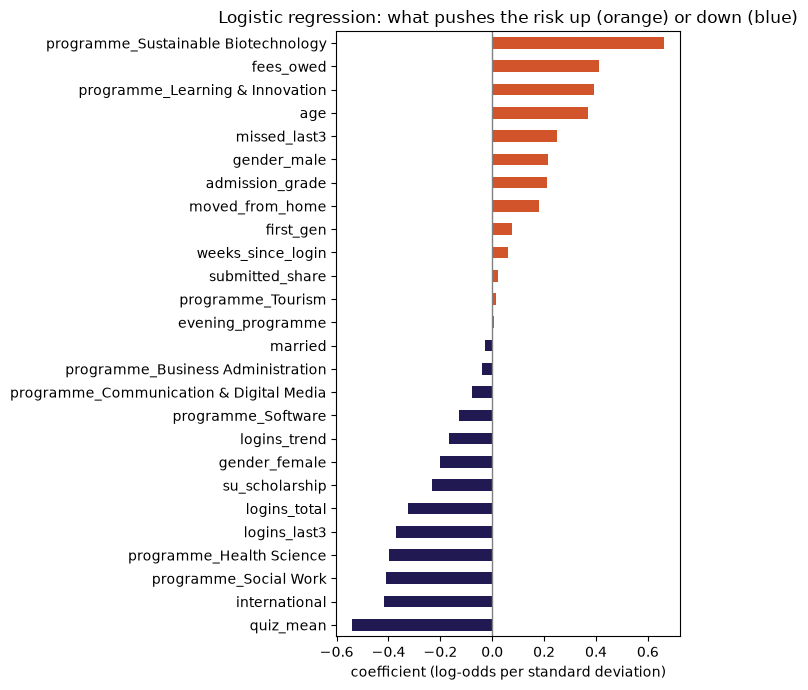

In [7]:
# 1 · which columns are numbers and which are text
categorical = ["programme", "gender"]
numeric = [c for c in features if c not in categorical]

# 2. preparation: fill gaps + scale the numbers, one-hot the categories
prepare = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), categorical)])

# 3.  pipeline = preparation + model; fit learns on 2023-2024 only
logit = make_pipeline(prepare, LogisticRegression(max_iter=2000))
logit.fit(train[features], train["left"])

# 4. predict risk for every 2025 student, and the AUC
val["risk_logit"] = logit.predict_proba(val[features])[:, 1]
print(f"logistic regression · validation AUC: {roc_auc_score(val['left'], val['risk_logit']):.3f}")
print(f"average predicted risk {val['risk_logit'].mean():.1%} vs actual share who left {val['left'].mean():.1%}")

# 5 · coefficients: which features push the risk up (+) or down (-)
names = [n.split("__", 1)[1] for n in logit[0].get_feature_names_out()]   # 'num__age' -> 'age'
coef = pd.Series(logit[-1].coef_[0], index=names).sort_values()
coef.plot.barh(figsize=(7, 7), color=["#D2542A" if c > 0 else "#211A52" for c in coef])
plt.axvline(0, color="grey", lw=1)
plt.title("Logistic regression: what pushes the risk up (orange) or down (blue)")
plt.xlabel("coefficient (log-odds per standard deviation)")
plt.tight_layout(); plt.show()

*Your answer:*

**How good is it?** If we take one student who left and one who stayed, the model gives the higher risk to the
one who left in **8 out of 10 cases** (AUC 0.81). It expects a bit more students to leave than really did
(8.6 % vs 6.9 %), because 2025 was a calmer year than the years it learned from.

**What raises the risk:** owing fees, missing recent assignments, being older, and some programmes
(Sustainable Biotechnology, Learning & Innovation).
**What lowers the risk:** good quiz scores, logging in often, an SU grant, and programmes like Health Science
and Social Work.

**Two cautions.** Each factor is judged *on top of the others*: handing in assignments, quiz scores and logins
all describe "how active is the student", so the model spreads the effect across them. And international
students come out as *less* at risk than domestic students with the same activity, which suggests that logins
may not mean the same for both groups (we check this in step 8). These are patterns, not causes.

✏️ **Your turn.** Train XGBoost the same way and compare the AUC. Pick one model and store its predictions for 2025 in `val['risk']`: all the next steps use it.

<details><summary>Hint</summary>

`make_pipeline(prepare, xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3))`. If you want the app to be as easy as the hotel app, use XGBoost there: the hotel's way of storing the model is written for XGBoost.
</details>

In [8]:
from sklearn.base import clone

# 1 · same preparation as the logistic regression, but a fresh copy
#     (clone = an unfitted copy, so the two models do not share the same object)
prepare_xgb = clone(prepare)

# 2 · pipeline = preparation + XGBoost: 300 small trees (max 3 questions each), small steps (5 %)
booster = make_pipeline(prepare_xgb,
                        xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0))
booster.fit(train[features], train["left"])          # learns on 2023-2024 only

# 3 · risk for every 2025 student, and the AUC
val["risk_xgb"] = booster.predict_proba(val[features])[:, 1]

# 4 · compare the two models: on the years they learned from (train) and on the new year (val)
compare = pd.DataFrame({
    "AUC train (2023-24)": [roc_auc_score(train["left"], logit.predict_proba(train[features])[:, 1]),
                            roc_auc_score(train["left"], booster.predict_proba(train[features])[:, 1])],
    "AUC validation (2025)": [roc_auc_score(val["left"], val["risk_logit"]),
                              roc_auc_score(val["left"], val["risk_xgb"])],
    "average risk 2025": [val["risk_logit"].mean(), val["risk_xgb"].mean()]},
    index=["logistic regression", "XGBoost"]).round(3)
print(f"actual share who left in 2025: {val['left'].mean():.3f}")
compare



actual share who left in 2025: 0.069


,AUC train (2023-24),AUC validation (2025),average risk 2025
logistic regression,0.823,0.809,0.086
XGBoost,0.945,0.788,0.084


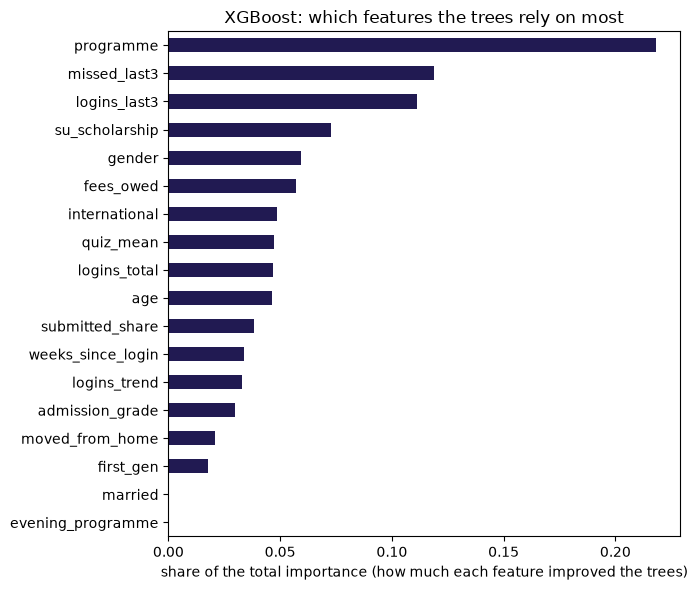

In [9]:
# 5 · XGBoost has no coefficients: instead we ask which features its trees used most ("importance")
names = [n.split("__", 1)[1] for n in booster[0].get_feature_names_out()]       # 'num__age' -> 'age'
importance = pd.Series(booster[-1].feature_importances_, index=names)

# the one-hot columns (programme_Software, programme_Tourism, ...) are added back to one feature: 'programme'
importance.index = [next(f for f in features if n == f or n.startswith(f + "_")) for n in importance.index]
importance = importance.groupby(level=0).sum().sort_values()
importance = importance / importance.sum()                                      # as a share of the total

importance.plot.barh(figsize=(7, 6), color="#211A52")
plt.title("XGBoost: which features the trees rely on most")
plt.xlabel("share of the total importance (how much each feature improved the trees)")
plt.tight_layout(); plt.show()

**XGBoost** does **not** beat the logistic regression here: validation AUC 0.79 against 0.81.
On the years it learned from it scores 0.94, much higher than on 2025: it has partly memorised the training
students (overfitting), while the logistic regression scores about the same on both (0.82 and 0.81).
With only about 150 students who left in the training years, there is not enough data for 300 trees to find
complex patterns, and the patterns that matter here are simple (fewer assignments, fees owed, fewer logins
-> higher risk), which a linear model already captures. A more complex model **is not automaticaly a better one.**

# We choose the Logistic Regression

In [10]:
# 6 · our choice: the logistic regression (higher validation AUC, no overfitting, easier to explain)
model = logit
val["risk"] = val["risk_logit"]
print(f"chosen model: logistic regression · validation AUC {roc_auc_score(val['left'], val['risk']):.3f}")

chosen model: logistic regression · validation AUC 0.809


---
## 5 · The mistakes: the confusion matrix ⚠️

**This is the core of the assignment.** Suppose the office talks to every student with a risk of at least 50 %.
Every student lands in one of four boxes:

| | **not contacted** | **contacted** |
|---|---|---|
| **stayed** | ✅ true negative (TN) | 📞 **false positive (FP)**: a false alarm, a worried student who was fine |
| **left** | 🚪 **false negative (FN)**: a missed student, nobody tried | 🎯 true positive (TP): reached in time |

| Question | Name | Formula |
|---|---|---|
| Of the students we contacted, how many were really at risk? | **precision** | TP / (TP + FP) |
| Of the students who left, how many did we reach? | **recall** | TP / (TP + FN) |
| Of the students who were fine, how many did we worry? | **false positive rate** | FP / (FP + TN) |
| How many students did we handle correctly? | **accuracy** | (TP + TN) / all |

✏️ **Your turn.** Count the four boxes for a 50 % cut-off, compute the four numbers, and write each as a sentence about students (*"of the students we contacted, … were really at risk"*). Then compute the accuracy of contacting **nobody**. What does it tell you about accuracy? (Template: *Reading the confusion matrix*, section 7 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

`TN, FP, FN, TP = confusion_matrix(val['left'], val['risk'] >= 0.5).ravel()`. Contacting nobody gets every student who stayed right, so its accuracy is `1 - val['left'].mean()`.
</details>

In [11]:
# 1 · the rule: contact every 2025 student with a risk of at least 50 %
cut = 0.5
contacted = val["risk"] >= cut                       # True = contacted, False = not contacted

# 2 · the four boxes: compare what the rule did with what really hapened
#     labels=[0, 1] keeps the order TN, FP, FN, TP even if a box is empty
TN, FP, FN, TP = confusion_matrix(val["left"], contacted, labels=[0, 1]).ravel()

# 3 · the boxes as a small table: rows = what happened, columns = what the office did
display(pd.DataFrame([[TN, FP], [FN, TP]],
                     index=["stayed", "left"], columns=["not contacted", "contacted"]))

# 4 · the four numbers
precision = TP / (TP + FP)
recall = TP / (TP + FN)
fpr = FP / (FP + TN)
accuracy = (TP + TN) / len(val)

# 5 · the same numbers as sentences about students
print(f"Rule: contact everyone with a risk of at least {cut:.0%} -> {TP + FP} students contacted")
print(f"  precision {precision:.0%}: of the students we contacted, {precision:.0%} were really at risk")
print(f"  recall    {recall:.0%}: of the {TP + FN} students who left, we reached {TP}; {FN} were missed")
print(f"  false positive rate {fpr:.0%}: of the students who were fine, {fpr:.0%} were worried for nothing")
print(f"  accuracy  {accuracy:.1%}")

# 6 · the trap: contacting NOBODY is right for every student who stayed
print(f"\nContacting nobody: accuracy {1 - val['left'].mean():.1%}, and reaches 0 of {val['left'].sum()} students who left")# your code here

,not contacted,contacted
stayed,863,9
left,54,11


Rule: contact everyone with a risk of at least 50% -> 20 students contacted
  precision 55%: of the students we contacted, 55% were really at risk
  recall    17%: of the 65 students who left, we reached 11; 54 were missed
  false positive rate 1%: of the students who were fine, 1% were worried for nothing
  accuracy  93.3%

Contacting nobody: accuracy 93.1%, and reaches 0 of 65 students who left


# Soo not a good cut off

*Your answer:* 

* With a 50 % cut-off the office would contact only **20 students**: 11 of them would really have
left (**reached in time**), 9 would have stayed anyway (**worried for nothing**). But **54 of the 65 students
who left would be missed**.

- **Precision 55 %:** of the students we contact, about half are really at risk.
- **Recall 17 %:** of the students who leave, we reach fewer than one in five.
- **False positive rate 1 %:** almost no student who was fine gets worried.
- **Accuracy 93.3 %.**

Accuracy looks excellent, but **contacting nobody scores 93.1 %**: because only 7 % of the students leave,
saying "everyone stays" is right 93 % of the time while helping no one. Accuracy rewards doing nothing, so it is
the wrong compass here. What the office cares about is *how many students at risk we reach* (recall) and
*how many conversations are well spent* (precision). 

✏️ **Your turn.** Now move the cut-off: make a small table for cut-offs 0.05, 0.1, 0.2, 0.3, 0.5 with the number contacted, the four boxes, precision and recall. What happens to the missed students and the false alarms as the cut-off goes down?

<details><summary>Hint</summary>

Write a function `boxes(cut)` that returns a dict with the counts and the rates, then `pd.DataFrame([boxes(c) for c in [0.05, 0.1, 0.2, 0.3, 0.5]])`.
</details>

In [12]:
# a function that counts the four boxes for any cut-off 
def boxes(cut, data=val):
    contacted = data["risk"] >= cut
    TN, FP, FN, TP = confusion_matrix(data["left"], contacted, labels=[0, 1]).ravel()
    return {"cut-off": cut,
            "contacted": TP + FP,
            "reached in time (TP)": TP,
            "worried for nothing (FP)": FP,
            "missed (FN)": FN,
            "left alone, fine (TN)": TN,
            "precision": TP / max(1, TP + FP),        # max(1, ...) avoids dividing by 0 if nobody is contacted
            "recall": TP / max(1, TP + FN)}

# one row per cut-off
table = pd.DataFrame([boxes(c) for c in [0.05, 0.1, 0.2, 0.3, 0.5]]).set_index("cut-off")
table.round(2)

,contacted,reached in time (TP),worried for nothing (FP),missed (FN),"left alone, fine (TN)",precision,recall
cut-off,,,,,,,
0.05,409,53,356,12,516,0.13,0.82
0.10,224,40,184,25,688,0.18,0.62
0.20,111,33,78,32,794,0.30,0.51
0.30,56,24,32,41,840,0.43,0.37
0.50,20,11,9,54,863,0.55,0.17


*Your answer:* Lowering the cut-off contacts more students: **missed students go down** (54 → 12) but
**false alarms go up much faster** (9 → 356). Recall rises (17 % → 82 %), precision falls (55 % → 13 %).
**No cut-off removes both mistakes**. .

---
## 6 · A cut-off from costs 💶

Which cut-off is right depends on what each mistake costs. These are **assumptions**; part of your job is to
question them.

- **A conversation** costs about **500 DKK** of adviser time.
- **A false alarm** costs a worried student. Say that is worth **2,000 DKK**.
- **A student who leaves** costs the university about **60,000 DKK** (and the student far more). A conversation
  does not save everyone: say it keeps **30 %** of the students at risk.

So contacting a student with risk *p* is worth on average **p × 0.30 × 60,000 − 500 − (1 − p) × 2,000**.

In [13]:
COST_TALK, COST_WORRY, COST_LEAVE, HELPS = 500, 2_000, 60_000, 0.30

✏️ **Your turn.** Compute the net value of the rule for cut-offs from 0.02 to 0.9, plot it, and find the best cut-off. How many students would the office contact? Then change one assumption (a false alarm worth 10,000 DKK, or conversations that help only 10 %) and see how the rule moves. Who should decide these numbers? (Template: *A threshold from costs*, section 7 of the hotel notebook (session 10).)

<details><summary>Hint</summary>

Net value at a cut-off = TP × HELPS × COST_LEAVE − (TP + FP) × COST_TALK − FP × COST_WORRY. Break-even: the formula above is zero at p = (500 + 2,000) / (0.30 × 60,000 + 2,000).
</details>

break-even: contact a student if the risk is above 12.5%
best cut-off on 2025: 20% -> net value 382,500 DKK
  111 students contacted: 33 reached in time, 78 worried for nothing, 32 missed
  for comparison, a 50 % cut-off: 170,000 DKK


,best cut-off,students contacted,net value (DKK)
scenario,,,
our assumptions,0.20,111,382500.0
"a false alarm costs 10,000 DKK",0.39,34,175000.0
a conversation helps only 10 %,0.33,48,72000.0


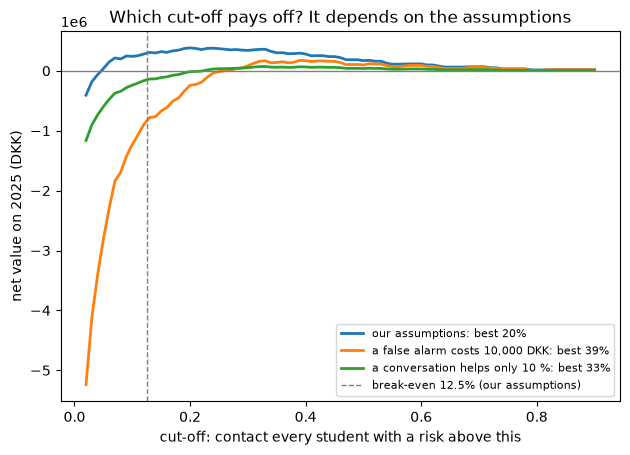

In [14]:
# the assumptions 
# COST_TALK, COST_WORRY, COST_LEAVE, HELPS = 500, 2_000, 60_000, 0.30

# 1 · net value of a rule "contact everyone with risk >= cut", on the 2025 students
def net_value(cut, talk=COST_TALK, worry=COST_WORRY, leave=COST_LEAVE, helps=HELPS, data=val):
    contacted = data["risk"] >= cut
    TP = (contacted & (data["left"] == 1)).sum()          # reached in time
    FP = (contacted & (data["left"] == 0)).sum()          # worried for nothing
    return TP * helps * leave - (TP + FP) * talk - FP * worry

# 2 · try every cut-off from 2 % to 90 % and keep the best one
cuts = np.round(np.arange(0.02, 0.91, 0.01), 2)
values = [net_value(c) for c in cuts]
best_cut = cuts[int(np.argmax(values))]
break_even = (COST_TALK + COST_WORRY) / (HELPS * COST_LEAVE + COST_WORRY)

b = boxes(best_cut)                                         # the function from step 5
print(f"break-even: contact a student if the risk is above {break_even:.1%}")
print(f"best cut-off on 2025: {best_cut:.0%} -> net value {max(values):,.0f} DKK")
print(f"  {b['contacted']} students contacted: {b['reached in time (TP)']} reached in time, "
      f"{b['worried for nothing (FP)']} worried for nothing, {b['missed (FN)']} missed")
print(f"  for comparison, a 50 % cut-off: {net_value(0.5):,.0f} DKK")

# 3 · change one assumption at a time and see how the best rule moves
scenarios = {"our assumptions": {},
             "a false alarm costs 10,000 DKK": {"worry": 10_000},
             "a conversation helps only 10 %": {"helps": 0.10}}
rows = []
for name, change in scenarios.items():
    vals = [net_value(c, **change) for c in cuts]
    c = cuts[int(np.argmax(vals))]
    contacted = (val["risk"] >= c).sum()
    rows.append({"scenario": name, "best cut-off": c, "students contacted": contacted, "net value (DKK)": max(vals)})
    plt.plot(cuts, vals, lw=2, label=f"{name}: best {c:.0%}")
display(pd.DataFrame(rows).set_index("scenario"))

# 4 · the picture
plt.axhline(0, color="grey", lw=1)
plt.axvline(break_even, color="grey", ls="--", lw=1, label=f"break-even {break_even:.1%} (our assumptions)")
plt.xlabel("cut-off: contact every student with a risk above this"); plt.ylabel("net value on 2025 (DKK)")
plt.title("Which cut-off pays off? It depends on the assumptions")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

*Your answer:* 

- A conversation pays off from a risk of **12.5 %**. On 2025 the best cut-off is **20 %**:
111 students contacted, 33 reached in time, 78 worried for nothing, 32 missed, worth about **380,000 DKK**.
It sits a bit above 12.5 % because the model slightly overestimates risk in 2025.

- The rule depends on the assumptions: if they change , a false alarm costs 10,000 DKK the best cut-off rises to 39 %
(34 students); if a conversation helps only 10 % it rises to 33 % (48 students). These numbers are value
judgements, so the university and the advisers should set them.

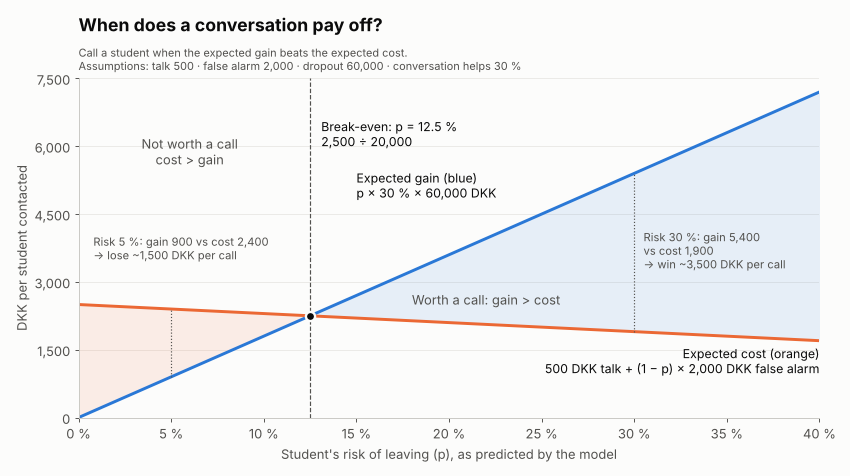

**The picture** shows the break even point: if the model's risks were exact, every student above **12.5 %** would be worth
a call. On the real 2025 students the best cut-off is higher (**20 %**).

---
## 7 · Only 40 conversations

The office can talk to **40** students at week 6. With a fixed capacity the rule becomes: **talk to the 40 with the
highest risk**. How many of the 40 were really at risk (**precision at 40**)? How many of all students who left were
among them (**recall at 40**)?

✏️ **Your turn.** Compute precision and recall at 40. How many conversations would you need to reach half of the students who leave? What would a fourth adviser (about 13 more conversations) buy?

<details><summary>Hint</summary>

`top = val.nlargest(40, 'risk')`; precision = `top['left'].mean()`; recall = `top['left'].sum() / val['left'].sum()`. Try other numbers instead of 40.
</details>

In [15]:
# 1 · rank the 2025 students by risk, highest first
ranked = val.sort_values("risk", ascending=False).reset_index(drop=True)
total_left = val["left"].sum()

# 2 · the rule with capacity: talk to the K students with the highest risk
def top_k(k):
    top = ranked.head(k)
    reached = top["left"].sum()
    return {"conversations": k,
            "reached in time": reached,
            "worried for nothing": k - reached,
            "missed": total_left - reached,
            "precision": reached / k,                    # of the k we talk to, share really at risk
            "recall": reached / total_left,              # of all who left, share we reached
            "lowest risk on the list": top["risk"].min()}

# 3 · the office rule: 40 conversations
t = top_k(40)
print(f"Top 40: {t['reached in time']} of the 40 really left (precision {t['precision']:.0%}); "
      f"we reach {t['reached in time']} of {total_left} who left (recall {t['recall']:.0%}).")
print(f"The 40th student has a risk of {t['lowest risk on the list']:.0%}: that is the cut-off the capacity sets.")
print(f"For comparison: 40 students picked at random would include about {40 * val['left'].mean():.1f} who leave.")

# 4 · how many conversations to reach half of the students who leave?
needed = int((ranked["left"].cumsum() >= np.ceil(total_left / 2)).idxmax()) + 1
print(f"To reach half of the students who leave ({int(np.ceil(total_left / 2))} of {total_left}) "
      f"we would need {needed} conversations.")

# 5 · what other capacities would buy (53 = a fourth adviser, about 13 more conversations)
display(pd.DataFrame([top_k(k) for k in [20, 40, 53, 80, 111]]).set_index("conversations").round(2))

Top 40: 20 of the 40 really left (precision 50%); we reach 20 of 65 who left (recall 31%).
The 40th student has a risk of 36%: that is the cut-off the capacity sets.
For comparison: 40 students picked at random would include about 2.8 who leave.
To reach half of the students who leave (33 of 65) we would need 109 conversations.


,reached in time,worried for nothing,missed,precision,recall,lowest risk on the list
conversations,,,,,,
20,11,9,54,0.55,0.17,0.50
40,20,20,45,0.50,0.31,0.36
53,24,29,41,0.45,0.37,0.31
80,29,51,36,0.36,0.45,0.24
111,33,78,32,0.30,0.51,0.20


*Your answer:* 

*Your answer:* With 40 conversations, **20 of the 40 students really left** (precision 50 %), against about
3 if they were picked at random: the model makes the list about seven times more useful. But we reach only
**20 of the 65 who left** (recall 31 %). Reaching half of them would take **109 conversations**.
A **fourth adviser**  would reach more students
by our assumptions. The office is limited by its capacity, not by the model.

---
## 8 · Fair to whom? ⚖️

About a fifth of the students are international. Compare the mistakes **per group** for the top-40 rule.

✏️ **Your turn.** For international and domestic students: the share who really leave, the average predicted risk, and the recall of the top-40 rule. Does the model get both groups right? Then compare how often each group logs in. Is a login the same signal for everyone? What would you tell the university?

<details><summary>Hint</summary>

Mark the top 40 first: `val['top40'] = val['risk'].rank(ascending=False) <= 40`. Then `val.groupby('international')[['left', 'risk']].mean()`; recall per group = among the students who left, the share with `top40`: `val[val['left'] == 1].groupby('international')['top40'].mean()`. Logins: `history.groupby('international')['logins_total'].mean()`.
</details>

In [16]:
#1 · mark the 40 highest risks of 2025 
val["top40"] = val["risk"].rank(ascending=False) <= 40

# 2 · per group (0 = domestic, 1 = international): who leaves, what the model predicts, who gets on the list
fair = val.groupby("international").agg(students=("left", "size"),
                                        left=("left", "sum"),
                                        share_who_left=("left", "mean"),
                                        average_predicted_risk=("risk", "mean"),
                                        on_top40_list=("top40", "sum"))
# recall per group: of the students who left, the share that was on the list
fair["recall_top40"] = val[val["left"] == 1].groupby("international")["top40"].mean()
# precision per group: of the students on the list, the share who really left
fair["precision_top40"] = val[val["top40"]].groupby("international")["left"].mean()
fair.index = ["domestic", "international"]
display(fair.round(3))

# 3 · is a login the same signal for everyone? average logins by group and by outcome (all three years)
logins = history.groupby(["international", "left"])[["logins_total", "logins_last3"]].mean().round(1)
logins.index = ["domestic, stayed", "domestic, left", "international, stayed", "international, left"]
display(logins)

,students,left,share_who_left,average_predicted_risk,on_top40_list,recall_top40,precision_top40
domestic,738,51,0.069,0.091,36,0.333,0.472
international,199,14,0.070,0.065,4,0.214,0.750


,logins_total,logins_last3
"domestic, stayed",37.5,18.3
"domestic, left",25.1,11.8
"international, stayed",24.2,11.7
"international, left",16.3,7.6


*Your answer:* 

- International and domestic students leave equally often (7 %), but the model does not treat
them the same. Only . **international students at risk are missed more often**.

- The reason seems to be logins: international students who *stay* log in as rarely as domestic students who
*leave*. A login does not mean the same for everyone. The numbers are small (14 international students who
left), so this must be checked again over more years.

**What we would tell the university:** do not treat few logins as a warning sign on its own; check the list
for each group every year; decide openly, as people, whether both groups should be reached equally often;
and always let an adviser look at the list before anyone is contacted.

# BEFORE 9

**Note on training data.** The model is trained on 2023–2024 only, and 2025 is kept as an unseen test year.
That is why all the numbers in this notebook (AUC, the four boxes, the top 40, the groups) are honest, and why
the app can show the mistakes on 2025 fairly. In real use, the model would be retrained on all available years
(including 2025) before the next semster, and checked again on every new cohort.

# IGNORE

The cell below writes `portable_logit.py`, the small loader for our stored model (the logistic-regression
version  `portable.py`), so that this notebook runs on its own, in Colab or locally.

In [17]:
%%writefile portable_logit.py
"""The logistic regression without pickles: preprocessing + coefficients as plain numbers (two JSON files).

Same idea as the hotel app's portable.py, but for make_pipeline(ColumnTransformer, LogisticRegression).
These files load with any recent pandas and numpy, on any Python, so the app needs no scikit-learn.

  export(pipe, folder)   -> writes preprocess.json + logit.json   (needs scikit-learn; run in the notebook)
  Model(folder)          -> .transform(df), .predict_proba(df), .contributions(df)   (needs only pandas, numpy)
"""
import json
from pathlib import Path

import numpy as np
import pandas as pd


def export(pipe, folder):
    """Turn a make_pipeline(ColumnTransformer[num: imputer+scaler, cat: one-hot], LogisticRegression) into files."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    prep, clf = pipe[0], pipe[-1]
    num_pipe, num_cols = prep.named_transformers_["num"], prep.transformers_[0][2]
    imputer, scaler = num_pipe[0], num_pipe[-1]
    onehot, cat_cols = prep.named_transformers_["cat"], prep.transformers_[1][2]
    infrequent = onehot.infrequent_categories_ or [None] * len(cat_cols)
    spec = {
        "numeric": [{"name": c, "median": float(imputer.statistics_[i]), "mean": float(scaler.mean_[i]),
                     "scale": float(scaler.scale_[i])} for i, c in enumerate(num_cols)],
        "categorical": [{"name": c,
                         "frequent": [str(v) for v in onehot.categories_[i] if infrequent[i] is None or v not in infrequent[i]],
                         "has_infrequent": infrequent[i] is not None}
                        for i, c in enumerate(cat_cols)],
        "columns": [n.split("__", 1)[1] for n in prep.get_feature_names_out()],
    }
    weights = {"intercept": float(clf.intercept_[0]),
               "coefficients": [float(w) for w in clf.coef_[0]]}      # same order as spec["columns"]
    (folder / "preprocess.json").write_text(json.dumps(spec, indent=1))
    (folder / "logit.json").write_text(json.dumps(weights, indent=1))


class Model:
    def __init__(self, folder):
        folder = Path(folder)
        self.spec = json.loads((folder / "preprocess.json").read_text())
        w = json.loads((folder / "logit.json").read_text())
        self.intercept = w["intercept"]
        self.coef = np.array(w["coefficients"])
        self.features = [n["name"] for n in self.spec["numeric"]] + [c["name"] for c in self.spec["categorical"]]

    def transform(self, df):
        """Same numbers the scikit-learn preprocessing produces: median-fill + standardise; one-hot with rare and
        unseen levels pooled into one column (as OneHotEncoder(handle_unknown='infrequent_if_exist'))."""
        parts = []
        for n in self.spec["numeric"]:
            x = pd.to_numeric(df[n["name"]], errors="coerce").astype(float).fillna(n["median"])
            parts.append(((x - n["mean"]) / n["scale"]).to_numpy()[:, None])
        for c in self.spec["categorical"]:
            v = df[c["name"]].astype(str).to_numpy()
            parts.append(np.stack([v == level for level in c["frequent"]], axis=1).astype(float))
            if c["has_infrequent"]:
                parts.append((~np.isin(v, c["frequent"])).astype(float)[:, None])
        return np.hstack(parts)

    def predict_proba(self, df):
        """Risk of leaving for each row (1-D array): sigmoid(intercept + sum of coefficient x value)."""
        z = self.intercept + self.transform(df) @ self.coef
        return 1 / (1 + np.exp(-z))

    def contributions(self, df):
        """Per-row push of each original feature on the log-odds (+ = towards leaving); one-hot columns summed back."""
        contrib = self.transform(df) * self.coef
        owner = [next(f for f in self.features if col == f or col.startswith(f + "_")) for col in self.spec["columns"]]
        return pd.DataFrame(contrib, columns=owner, index=df.index).T.groupby(level=0).sum().T[self.features]

Overwriting portable_logit.py


---
## 9 · Store the model

The app needs your model as files. Do it the way the hotel notebook (session 10) does in section 9, *Storing the model properly*: the
**portable copy** (`preprocess.json` + `booster.json`) loads in the app with any Python version, which a pickle does
not. The hotel app's `portable.py` does both the saving and the loading, for a pipeline built like the one in step 4.

✏️ **Your turn.** Save your XGBoost pipeline into a folder `model`, load it back with `portable.Model`, and check that it gives the same predictions. Download the folder as a zip. You will put it into your app's repository.

<details><summary>Hint</summary>

```python
import urllib.request, shutil
urllib.request.urlretrieve("https://raw.githubusercontent.com/aaubs/tonights-front-desk/main/portable.py", "portable.py")
import portable
os.makedirs("model", exist_ok=True)
portable.export(booster, "model")
back = portable.Model("model").predict_proba(val)
print(np.allclose(back, booster.predict_proba(val[features])[:, 1], atol=1e-5))
shutil.make_archive("model", "zip", "model")   # then download model.zip (Colab: the folder icon on the left)
```
</details>

In [18]:
import importlib, shutil
import portable_logit                                   # the file next to this notebook
importlib.reload(portable_logit)                        # picks up the file again if you change it

# 1 · save the chosen model (the logistic regression) as two plain JSON files in a folder 'model'
portable_logit.export(model, "model")
print("saved:", sorted(os.listdir("model")))

# 2 · load it back the way the app will: no scikit-learn, only pandas + numpy
app_model = portable_logit.Model("model")
back = app_model.predict_proba(val)

# 3 · check: the saved model must give the same risks as the one in this notebook
same = np.allclose(back, model.predict_proba(val[features])[:, 1], atol=1e-6)
print("same predictions as the notebook model:", same)

# 4 · zip the folder, to upload it to the app's GitHub repository later
shutil.make_archive("model", "zip", "model")
print("model.zip is ready next to this notebook")

saved: ['logit.json', 'preprocess.json']
same predictions as the notebook model: True
model.zip is ready next to this notebook


*Note:* We store the logistic regression in two JSON files (`preprocess.json` for the data preparation, `logit.json` for the coefficients).
`portable_logit.py` reads them with pandas and numpy only, so the app runs with any Python version.
The check confirms that the stored model gives exactly the same risks as the one trained here.

---
## 10 · This week's list

Now use the model the way the office would: on the 2026 students at the end of week 6.

✏️ **Your turn.** Predict the risk for every student in `new`, and show the 40 students the office should talk to this week. Would you send all 40 the same message? Is there anyone you would *not* contact?

<details><summary>Hint</summary>

`new['risk'] = booster.predict_proba(new[features])[:, 1]`, then `new.nlargest(40, 'risk')`.
</details>

In [19]:
# 1 · risk for every 2026 student, with the stored model (exactly what the app will use)
new["risk"] = app_model.predict_proba(new)

# 2 · the main reason each student is on the list: the factor that pushes their risk up the most
push = app_model.contributions(new)                 # per student: + pushes towards leaving, - away from it
new["main_reason"] = push.idxmax(axis=1)            # the column with the biggest push upwards

# 3 · this week's list: the 40 highest risks
top40 = new.nlargest(40, "risk")
print(f"{len(new)} students this week · average risk {new['risk'].mean():.1%}")
print(f"top 40: risk from {top40['risk'].min():.0%} to {top40['risk'].max():.0%} · "
      f"expected to leave among them ≈ {top40['risk'].sum():.0f} (the model overestimated a bit in 2025)")
print(f"international students on the list: {top40['international'].sum()} of 40 "
      f"(they are {new['international'].mean():.0%} of all students)")
print("\nmain reason on the list:", top40["main_reason"].value_counts().to_dict())

cols = ["student_id", "risk", "main_reason", "programme", "international", "fees_owed",
        "submitted_share", "missed_last3", "logins_last3", "quiz_mean", "weeks_since_login", "age"]
top40[cols].round(2).reset_index(drop=True)

703 students this week · average risk 8.6%
top 40: risk from 30% to 87% · expected to leave among them ≈ 18 (the model overestimated a bit in 2025)
international students on the list: 5 of 40 (they are 19% of all students)

main reason on the list: {'quiz_mean': 12, 'fees_owed': 10, 'age': 6, 'missed_last3': 4, 'programme': 4, 'logins_last3': 4}


,student_id,risk,main_reason,programme,international,fees_owed,submitted_share,missed_last3,logins_last3,quiz_mean,weeks_since_login,age
0,S260648,0.87,quiz_mean,Tourism,0,1,0.17,3.0,3.0,36.00,0.0,24
1,S260271,0.86,quiz_mean,Communication & Digital Media,0,1,0.33,3.0,6.0,37.00,1.0,20
2,S260458,0.84,fees_owed,Communication & Digital Media,0,1,0.50,1.0,0.0,53.67,3.0,20
3,S260606,0.71,age,Business Administration,0,0,0.50,3.0,4.0,53.33,1.0,39
4,S260095,0.69,quiz_mean,Sustainable Biotechnology,0,0,0.50,1.0,13.0,39.00,0.0,44
5,S260525,0.61,age,Business Administration,0,0,0.33,3.0,7.0,56.00,0.0,41
6,S260281,0.59,quiz_mean,Business Administration,0,0,0.50,2.0,8.0,37.33,0.0,38
7,S260548,0.55,quiz_mean,Sustainable Biotechnology,0,0,0.17,3.0,8.0,50.00,0.0,30
8,S260223,0.55,quiz_mean,Social Work,0,1,0.67,2.0,7.0,42.25,0.0,18
9,S260037,0.53,quiz_mean,Communication & Digital Media,0,0,0.50,2.0,3.0,50.33,2.0,23


# Example: Student S260648, Risk 0.87%

Student S260648 · Tourism · risk of leaving: 87% (rank 1 of 703)

What raises the risk most:
  ↑ average quiz score: 36 (typical: 64)
  ↑ owes fees: yes (typical: no)
  ↑ assignments missed (last 3 weeks): 3 (typical: 0)
  ↑ logins (last 3 weeks): 3 (typical: 16)
  ↑ logins (weeks 1-6): 11 (typical: 33)

What lowers the risk:
  ↓ admission grade: 4 (typical: 7)
  ↓ moved from home: no (typical: yes)
  ↓ share of assignments handed in: 17% (typical: 83%)


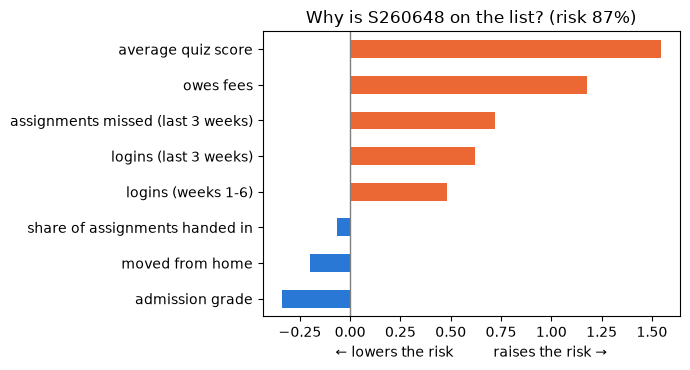

In [20]:
# plain-language names for the features (what the study office would call them)
LABELS = {"quiz_mean": "average quiz score", "fees_owed": "owes fees", "missed_last3": "assignments missed (last 3 weeks)",
          "logins_last3": "logins (last 3 weeks)", "logins_total": "logins (weeks 1-6)", "logins_trend": "change in logins",
          "submitted_share": "share of assignments handed in", "weeks_since_login": "weeks since last login",
          "su_scholarship": "SU grant", "age": "age", "admission_grade": "admission grade", "programme": "programme",
          "gender": "gender", "international": "international student", "first_gen": "first in family at university",
          "moved_from_home": "moved from home", "married": "married", "evening_programme": "evening programme"}
YES_NO = {"fees_owed", "su_scholarship", "international", "first_gen", "moved_from_home", "married", "evening_programme"}

def show(col, value):
    """Show a value the way a person would say it: yes/no, a percentage, or a number."""
    if col in YES_NO: return "yes" if value == 1 else "no"
    if col == "submitted_share": return f"{value:.0%}"
    return f"{value:.0f}" if isinstance(value, (int, float, np.integer, np.floating)) else str(value)

def explain(student_id, data=new, n=5):
    """Explain one student's risk in plain words: what pushes it up, what pulls it down."""
    row = data[data["student_id"] == student_id]
    push = app_model.contributions(row).iloc[0].sort_values()            # + towards leaving, - away from it
    risk = row["risk"].iloc[0]
    typical = data[features].median(numeric_only=True)                   # a typical student this year
    s = row.iloc[0]

    # 1 · the headline
    print(f"Student {student_id} · {s['programme']} · risk of leaving: {risk:.0%} "
          f"(rank {int((data['risk'] > risk).sum()) + 1} of {len(data)})\n")

    # 2 · the reasons, each compared with a typical student
    print("What raises the risk most:")
    for col in push[push > 0.05].index[::-1][:n]:
        t = f" (typical: {show(col, typical[col])})" if col in typical else ""
        print(f"  ↑ {LABELS[col]}: {show(col, s[col])}{t}")
    print("\nWhat lowers the risk:")
    for col in push[push < -0.05].index[:3]:
        t = f" (typical: {show(col, typical[col])})" if col in typical else ""
        print(f"  ↓ {LABELS[col]}: {show(col, s[col])}{t}")

    # 3 · the picture: the biggest pushes up (orange) and down (blue)
    keep = list(push.head(3).index) + list(push.tail(n).index)
    top = push[push.index.isin(keep) & (push.abs() > 0.05)]
    top.index = [LABELS[c] for c in top.index]
    top.plot.barh(figsize=(7, 3.8), color=["#eb6834" if v > 0 else "#2a78d6" for v in top])
    plt.axvline(0, color="grey", lw=1)
    plt.title(f"Why is {student_id} on the list? (risk {risk:.0%})")
    plt.xlabel("← lowers the risk          raises the risk →")
    plt.tight_layout(); plt.show()

explain("S260648")

# Final  🎉  😄
*Your answer:* Among the 703 students of 2026, the 40 highest risks range from 30 % to 87 %. If the model is
as good as on 2025, about **half of them**  would leave without help. Five of the 40 are
international (they are 20 % of all students; step 8 showed the model misses them more often).

**Not the same message for all 40.** The main reason differs: 16 are on the list mainly because of low quiz
scores or missed assignments (offer academic help: study groups, tutoring); 10 mainly because of fees owed
(offer financial advice: SU grant, a payment plan); 4 because of few logins (a simple "how is it going?").

**Whom we would not contact without a closer look:** about 10 students are on the list mainly because of their
age or their programme, things they cannot change. Being contacted "because you are older" would feel 
incorret and strange, so an adviser should first check if there are also  other signs.
Students who have not logged in for a week or more may already have left or be in a serious situation: they
deserve a personal call, not a standard e-mail. In every case the message should offer help and be friendly, never say
"our system thinks you will drop out", and an adviser, not the model, decides who is contacted.

# **Thank you for reading!** 😊

---
## 11 · Build the app 🛠️

Now build a Streamlit app for someone at the study office who is **not** a data scientist. Use the hotel app as your
template: [github.com/aaubs/tonights-front-desk](https://github.com/aaubs/tonights-front-desk) (`app.py`, `portable.py`,
`requirements.txt`, `model/`).

Your app should at least show:

1. **This week's list**: the 2026 students, ranked by risk, with the top 40 marked.
2. **The mistakes of a rule**: a slider (cut-off, or number of conversations) and, on the 2025 cohort, the four boxes
   in plain words ("12 students reached in time, 28 worried for nothing, 30 missed"), precision and recall.
3. **Per group**: the same numbers for international and domestic students.
4. **One thing of your own** that would help the office decide (for example the costs from step 6 as inputs, or why
   a student is on the list).

The app can read the data straight from GitHub, like this notebook (`URL + "new_week6.csv"`).

**Deploy:** create a public GitHub repository with `app.py`, `portable.py`, `requirements.txt` (`streamlit`,
`pandas`, `xgboost-cpu`, no version numbers) and your `model/` folder; then on
[share.streamlit.io](https://share.streamlit.io): *Create app* → your repository → `app.py`.